In [1]:
# ==================================
# IMPORTS
# ==================================
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parents[1]

sys.path.append(str(PROJECT_ROOT))

import torch
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from core.fno import FNO2d
from flow.cavity_driven.dataset import CavityDrivenDataset
from flow.cavity_driven.solver import solve_cavity_driven
from configs.settings import FLOW_DIR, CAVITY_DRIVEN_DIR

In [2]:
# ==================================
# DEVICE
# ==================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using:", device)

Using: mps


In [9]:
# ==================================
# LOAD CHECKPOINT
# ==================================

checkpoint = torch.load(
    "checkpoints/best_fno_64_no_sub_8.pt",
    map_location=device
)

print("Checkpoint Loaded...")

Checkpoint Loaded...


In [10]:
# ==================================
# LOAD MODEL
# ==================================

model = FNO2d(
    modesx=checkpoint["modesx"],
    modesy=checkpoint["modesy"],
    width=checkpoint["width"],
    in_channels=checkpoint["in_channels"],
    out_channels=checkpoint["out_channels"],
    n_layers=8,
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Model Loaded")

Model Loaded


In [11]:
# ==================================
# LOAD DATASET
# ==================================

dataset = CavityDrivenDataset(
    "data/cavity_dataset_200_no_subsampling.pt"
)

print("Dataset Loaded...")

Dataset Loaded...


In [12]:
idx = 342

sample = dataset[idx]

a = sample["a"].unsqueeze(0).to(device)

target = sample["u"]

In [13]:
with torch.no_grad():

    pred = model(a)

pred = pred.squeeze(0).cpu()

In [14]:
u_true = (
    target[0]
    * dataset.u_std
    + dataset.u_mean
)

v_true = (
    target[1]
    * dataset.v_std
    + dataset.v_mean
)

u_pred = (
    pred[0]
    * dataset.u_std
    + dataset.u_mean
)

v_pred = (
    pred[1]
    * dataset.v_std
    + dataset.v_mean
)

In [15]:
mse_u = torch.mean(
    (u_pred - u_true)**2
)

mse_v = torch.mean(
    (v_pred - v_true)**2
)

print("u mse =", mse_u.item())
print("v mse =", mse_v.item())

u mse = 7.431789299516822e-07
v mse = 1.9349448621142074e-07


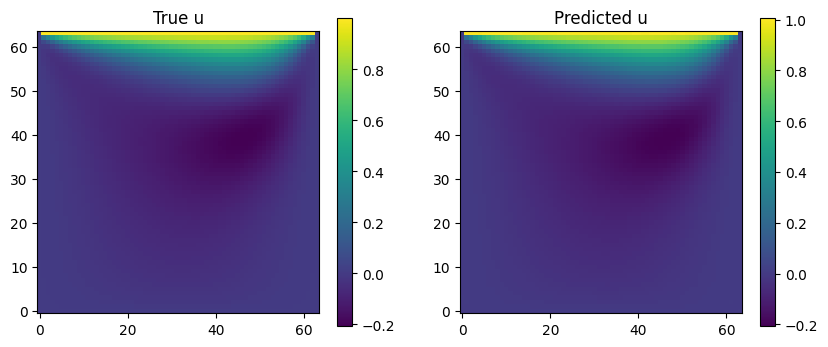

In [16]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(10,4)
)

im0 = ax[0].imshow(
    u_true,
    origin="lower"
)

ax[0].set_title(
    "True u"
)

plt.colorbar(
    im0,
    ax=ax[0]
)

im1 = ax[1].imshow(
    u_pred,
    origin="lower"
)

ax[1].set_title(
    "Predicted u"
)

plt.colorbar(
    im1,
    ax=ax[1]
)

plt.show()

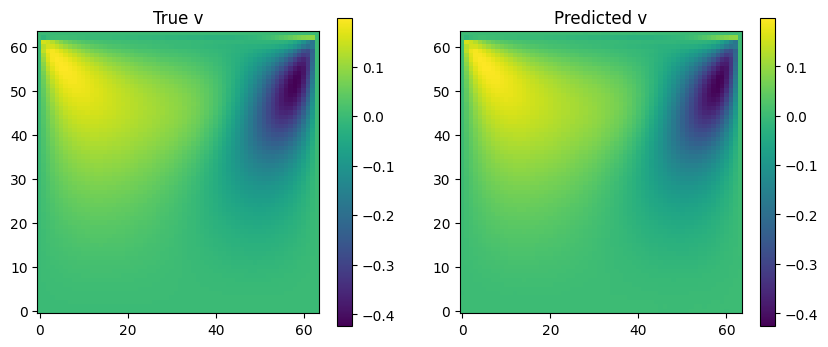

In [17]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(10,4)
)

im0 = ax[0].imshow(
    v_true,
    origin="lower"
)

ax[0].set_title(
    "True v"
)

plt.colorbar(
    im0,
    ax=ax[0]
)

im1 = ax[1].imshow(
    v_pred,
    origin="lower"
)

ax[1].set_title(
    "Predicted v"
)

plt.colorbar(
    im1,
    ax=ax[1]
)

plt.show()

In [18]:
speed_true = torch.sqrt(
    u_true**2 + v_true**2
)

speed_pred = torch.sqrt(
    u_pred**2 + v_pred**2
)

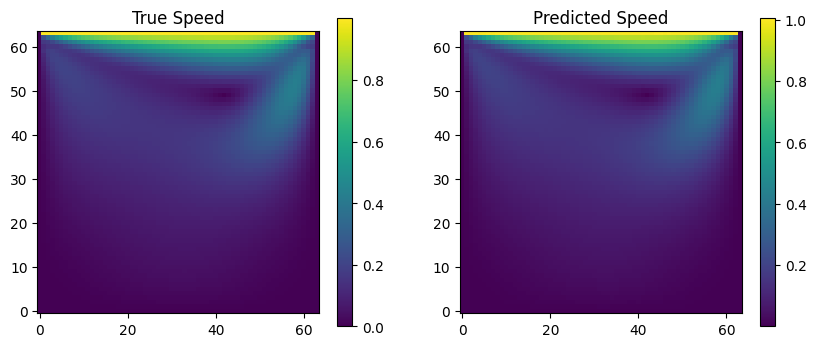

In [19]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(10,4)
)

im0 = ax[0].imshow(
    speed_true,
    origin="lower"
)

ax[0].set_title(
    "True Speed"
)

plt.colorbar(
    im0,
    ax=ax[0]
)

im1 = ax[1].imshow(
    speed_pred,
    origin="lower"
)

ax[1].set_title(
    "Predicted Speed"
)

plt.colorbar(
    im1,
    ax=ax[1]
)

plt.show()

In [20]:
x = dataset.x.numpy()
y = dataset.y.numpy()

X, Y = torch.meshgrid(
    dataset.x,
    dataset.y,
    indexing="xy"
)

X = X.numpy()
Y = Y.numpy()

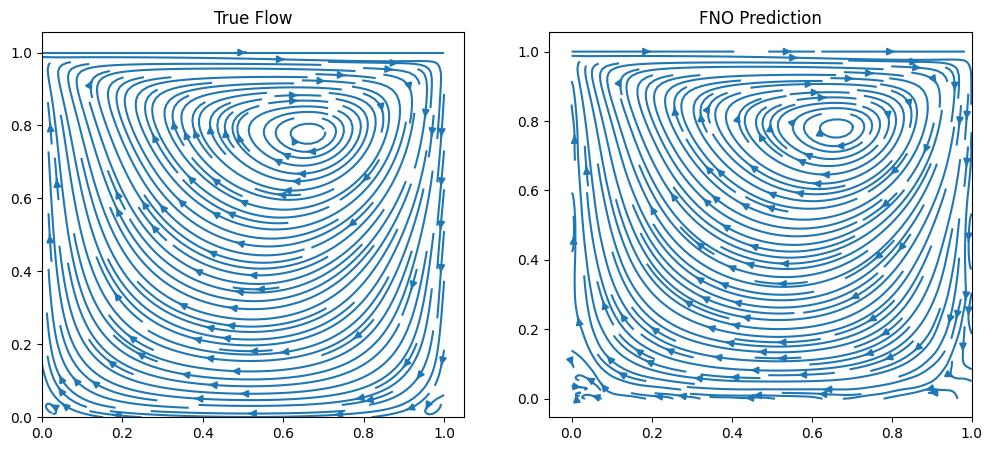

In [21]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12,5)
)

ax[0].streamplot(
    X,
    Y,
    u_true.numpy(),
    v_true.numpy(),
    density=2
)

ax[0].set_title(
    "True Flow"
)

ax[1].streamplot(
    X,
    Y,
    u_pred.numpy(),
    v_pred.numpy(),
    density=2
)

ax[1].set_title(
    "FNO Prediction"
)

plt.show()

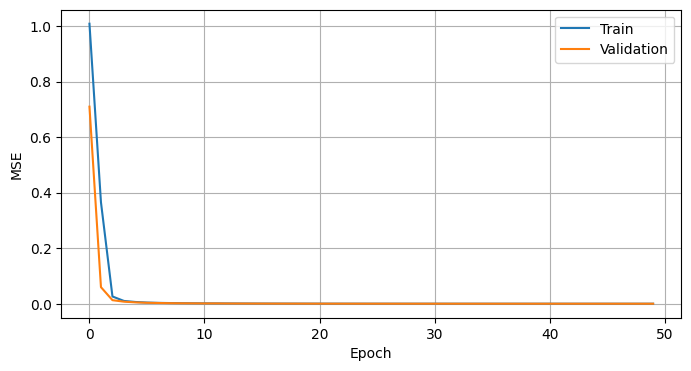

In [22]:
plt.figure(
    figsize=(8,4)
)

plt.plot(
    checkpoint["train_history"],
    label="Train"
)

plt.plot(
    checkpoint["val_history"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.legend()

plt.grid()

plt.show()